# F26-11 — Phase 2: Data Acquisition, Preprocessing and EDA
**Lightweight Speech Emotion Recognition: Cross-Dataset Generalization and Gender-Bias Analysis**

AI2002 Artificial Intelligence (BS-SE-5A), FAST-NUCES Lahore, Fall 2026 · Track B (Research & Development)
Members: 22L-7786 (Lead), 23L-3002, 23L-3102 · Instructor: Hajra Waheed

This notebook covers Phase 2 of the project: it collects the two datasets, checks their quality,
maps them to one label set, explores them, and turns every clip into the model-ready feature matrix used
by the base paper (Chowdhury et al., *Scientific Reports* 15, 11824, 2025). The reusable code lives in
`src/ser/` (`data.py` = indexing and labels, `features.py` = preprocessing and features); this notebook
calls it and documents every step.

In [1]:
import hashlib
import subprocess
import sys
import zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from ser.data import EMOTIONS, RAVDESS_CODES, TESS_CODES, index_ravdess, index_tess  # noqa: E402
from ser import features as F  # noqa: E402

DATA = ROOT / "data"
FEAT = ROOT / "features"
FIG = ROOT / "phase2" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
COLORS = dict(zip(EMOTIONS, plt.cm.tab10.colors))


def show(df):
    """Pretty table in Jupyter, plain text when run as a script."""
    try:
        from IPython.display import display
        display(df)
    except ImportError:
        print(df.to_string())


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


print("project root:", ROOT)
print("librosa", librosa.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

project root: C:\Users\user\Desktop\Ai-project
librosa 0.11.0 | numpy 2.2.5 | pandas 2.2.3


## 1. Data sources and collection method

| Dataset | Source | Content | Role in project |
|---|---|---|---|
| **RAVDESS** (Livingstone & Russo, 2018, CC BY-NC-SA 4.0) | Kaggle `uwrfkaggler/ravdess-emotional-speech-audio`; official copy on Zenodo (record 1188976) | 1,440 speech clips, 24 professional actors (12 M / 12 F), 8 emotions, 2 intensities | training, within-dataset tests, speaker-independent tests, gender-bias check |
| **TESS** (Pichora-Fuller & Dupuis, 2020) | Kaggle `ejlok1/toronto-emotional-speech-set-tess`; official copy on U of T Dataverse (doi:10.5683/SP2/E8H2MF) | 2,800 clips, 2 female speakers (aged 26 and 64), 7 emotions, 200 target words | unseen cross-dataset test set |

**Collection method.** Both are public, labelled research corpora recorded in a studio by actors, so no
scraping or manual labelling is needed: the emotion label is encoded in each file name. We download the
raw `.wav` files from a public repository. The official servers (Zenodo/Dataverse) were throttled to
~35 KB/s on our connection, so we used Hugging Face mirrors of the same files
(`birgermoell/ravdess`, `myleslinder/tess`) and verified that they match the originals: 1,440 RAVDESS
files with the original `03-01-…` names and sizes, and 2,800 TESS files. The cell below downloads the data
only if `data/` is missing; Kaggle downloads placed in `data/RAVDESS` and `data/TESS` work the same way.

In [2]:
HF = "https://huggingface.co/datasets"


def download_datasets():
    import json
    import urllib.request
    from concurrent.futures import ThreadPoolExecutor

    def fetch(url, dest):
        dest.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, dest)

    if not (DATA / "RAVDESS").exists():
        files = []
        for a in range(1, 25):
            with urllib.request.urlopen(f"https://huggingface.co/api/datasets/birgermoell/ravdess/tree/main/Actor_{a:02d}") as r:
                files += [x["path"] for x in json.load(r) if x["path"].endswith(".wav")]
        with ThreadPoolExecutor(16) as ex:
            list(ex.map(lambda p: fetch(f"{HF}/birgermoell/ravdess/resolve/main/{p}", DATA / "RAVDESS" / p), files))
    if not (DATA / "TESS").exists():
        z = DATA / "raw" / "tess.zip"
        fetch(f"{HF}/myleslinder/tess/resolve/main/data/tess.zip", z)
        zipfile.ZipFile(z).extractall(DATA / "TESS")


download_datasets()
all_wavs = {name: sorted((DATA / name).rglob("*.wav")) for name in ("RAVDESS", "TESS")}
for name, files in all_wavs.items():
    size = sum(p.stat().st_size for p in files) / 2**20
    print(f"{name}: {len(files)} .wav files, {size:.0f} MB on disk")

RAVDESS: 1440 .wav files, 563 MB on disk


TESS: 2800 .wav files, 268 MB on disk


## 2. Labels: decoding file names and building one label set

* **RAVDESS** name `03-01-05-02-01-01-12.wav` = modality (03 = audio only) – channel (01 = speech) –
  **emotion** – intensity – statement – repetition – **actor** (odd = male, even = female).
* **TESS** name `OAF_back_angry.wav` = speaker (OAF = older, YAF = younger) – word – **emotion**.

RAVDESS has 8 emotions and TESS has 7; RAVDESS has *calm*, which TESS lacks. Following the base paper
(its Table 1 lists 288 neutral RAVDESS clips = 96 neutral + 192 calm), we merge *calm* into *neutral*, giving
one 7-class set: neutral, happy, sad, angry, fearful, disgust, surprised. TESS `fear` → fearful and
`ps` (pleasant surprise) → surprised.

In [3]:
raw_rav = Counter(RAVDESS_CODES[p.stem.split("-")[2]] for p in all_wavs["RAVDESS"])
raw_tess = Counter(p.stem.split("_")[-1].lower() for p in all_wavs["TESS"])
show(pd.DataFrame({"RAVDESS (raw)": pd.Series(raw_rav), "TESS (raw)": pd.Series(raw_tess)}).fillna(0).astype(int))

rav = index_ravdess(DATA / "RAVDESS")
tess = index_tess(DATA / "TESS")
meta = pd.concat([rav, tess], ignore_index=True)
print(f"indexed: RAVDESS {len(rav)} clips, TESS {len(tess)} clips")
show(meta.drop(columns="path").groupby("dataset").head(3))

,RAVDESS (raw),TESS (raw)
angry,192,400
calm,192,0
disgust,192,400
fear,0,400
fearful,192,0
happy,192,400
neutral,96,400
ps,0,400
sad,192,400
surprised,192,0


indexed: RAVDESS 1440 clips, TESS 2800 clips


,dataset,emotion,label,speaker,actor,gender,intensity
0,RAVDESS,neutral,0,R01,1,male,normal
1,RAVDESS,neutral,0,R01,1,male,normal
2,RAVDESS,neutral,0,R01,1,male,normal
1440,TESS,angry,3,OAF,-1,female,n/a
1441,TESS,disgust,5,OAF,-1,female,n/a
1442,TESS,fearful,4,OAF,-1,female,n/a


## 3. Data quality checks

Before any modelling we check: unreadable or empty files, missing labels, exact duplicate files (some
Kaggle copies contain every file twice in nested folders, which would leak test clips into training),
file-name anomalies, sampling rate / channels, and silent clips.

In [4]:
def audio_info(path):
    i = sf.info(path)
    y, _ = sf.read(path, dtype="float32")
    return {"sr": i.samplerate, "channels": i.channels, "duration_s": i.duration,
            "subtype": i.subtype, "peak": float(np.abs(y).max()),
            "md5": hashlib.md5(Path(path).read_bytes()).hexdigest()}


info = pd.DataFrame([audio_info(p) for p in meta["path"]])
meta = pd.concat([meta, info], axis=1)

checks = pd.DataFrame({
    "clips": meta.groupby("dataset").size(),
    "missing labels": meta.groupby("dataset")["emotion"].apply(lambda s: s.isna().sum()),
    "duplicate names": meta.groupby("dataset")["path"].apply(lambda s: s.map(lambda p: Path(p).name.lower()).duplicated().sum()),
    "duplicate content (md5)": meta.groupby("dataset")["md5"].apply(lambda s: s.duplicated().sum()),
    "silent (peak < 1e-3)": meta.groupby("dataset")["peak"].apply(lambda s: (s < 1e-3).sum()),
    "sampling rate (Hz)": meta.groupby("dataset")["sr"].agg(lambda s: ", ".join(map(str, sorted(s.unique())))),
    "channels": meta.groupby("dataset")["channels"].agg(lambda s: ", ".join(map(str, sorted(s.unique())))),
    "format": meta.groupby("dataset")["subtype"].agg(lambda s: ", ".join(sorted(s.unique()))),
})
show(checks.T)
odd = [Path(p).name for p in tess["path"] if not Path(p).name.upper().startswith(("OAF_", "YAF_"))]
print("TESS files with a non-standard speaker prefix:", odd or "none")
print("cross-dataset content duplicates:", meta["md5"].duplicated().sum())

dataset,RAVDESS,TESS
clips,1440,2800
missing labels,0,0
duplicate names,0,0
duplicate content (md5),1,0
silent (peak < 1e-3),0,0
sampling rate (Hz),48000,"24414, 96000"
channels,"1, 2",1
format,PCM_16,PCM_16


TESS files with a non-standard speaker prefix: none
cross-dataset content duplicates: 1


In [5]:
# Details of the three anomalies found above.
dup = meta[meta.md5.duplicated(keep=False)]
print("identical audio under two names:")
show(dup.assign(file=dup.path.map(lambda p: Path(p).name))[["file", "emotion", "speaker", "duration_s"]])
stereo = meta[meta.channels == 2]
print(f"stereo files ({len(stereo)}):", [Path(p).name for p in stereo.path])
odd_sr = meta[(meta.dataset == "TESS") & (meta.sr != 24414)]
print("TESS files not at 24,414 Hz:", [(Path(p).name, sr) for p, sr in zip(odd_sr.path, odd_sr.sr)])

# Does the duplicate pair end up on both sides of the paper's random split? (checked again in Sec. 7)
dup_idx = [i for i, p in enumerate(rav.path) if p in set(dup.path)]
print("RAVDESS row indices of the pair:", dup_idx)

identical audio under two names:


,file,emotion,speaker,duration_s
374,03-01-03-01-02-01-07.wav,happy,R07,3.403396
375,03-01-03-01-02-02-07.wav,happy,R07,3.403396


stereo files (5): ['03-01-02-01-01-02-01.wav', '03-01-08-01-02-02-01.wav', '03-01-02-01-02-02-05.wav', '03-01-03-01-02-01-20.wav', '03-01-06-01-01-02-20.wav']
TESS files not at 24,414 Hz: [('OAF_food_fear.wav', 96000)]
RAVDESS row indices of the pair: [374, 375]


**How the anomalies are handled.** We verified our RAVDESS copy against the CRC32 checksums in the official
Zenodo archive: all 1,440 files are bit-identical, so these anomalies are part of the official release,
not download errors.

* **Stereo files (5 in RAVDESS):** the loader converts every clip to mono (`librosa.load(mono=True)`
  averages the channels), so all inputs are single-channel.
* **Mixed sampling rates** (RAVDESS 48 kHz, TESS 24,414 Hz, one TESS file at 96 kHz): every clip is
  resampled to 22,050 Hz, so all feature matrices are on the same time/frequency grid.
* **One duplicated recording** (Actor 07, *happy*, statement 2, repetitions 1 and 2 are the same audio):
  we keep both files so our data matches the paper's 1,440 clips, and track the pair through the splits
  (Sec. 7). In the paper's random split one copy lands in training and the other in validation, so no
  test clip is affected; in the speaker-independent protocol both copies belong to the same actor and
  always stay on the same side.

## 4. Exploratory data analysis (raw audio)
### 4.1 Class balance

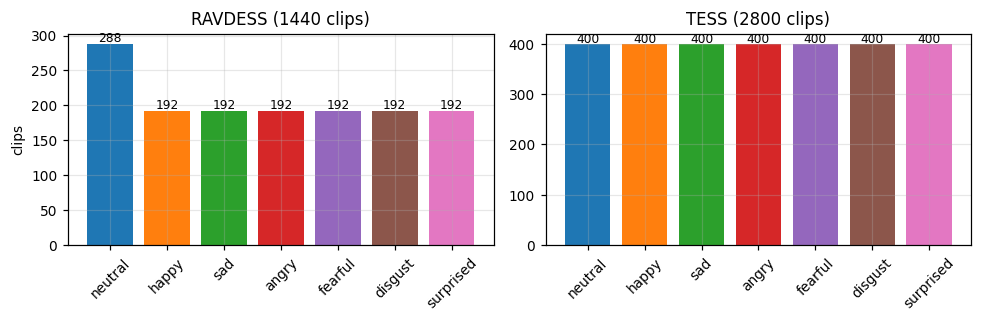

dataset,RAVDESS,TESS
emotion,,
neutral,288,400
happy,192,400
sad,192,400
angry,192,400
fearful,192,400
disgust,192,400
surprised,192,400


In [6]:
counts = meta.groupby(["emotion", "dataset"]).size().unstack().reindex(EMOTIONS)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for a, d in zip(ax, ["RAVDESS", "TESS"]):
    a.bar(counts.index, counts[d], color=[COLORS[e] for e in counts.index])
    for i, v in enumerate(counts[d]):
        a.text(i, v + 3, str(v), ha="center", fontsize=8)
    a.set_title(f"{d} ({counts[d].sum()} clips)")
    a.tick_params(axis="x", rotation=45)
ax[0].set_ylabel("clips")
savefig("fig1_class_balance")
show(counts)

In [7]:
print("RAVDESS speakers / gender:")
show(rav.groupby("gender").agg(actors=("actor", "nunique"), clips=("path", "size")))
show(pd.crosstab(rav["emotion"], [rav["gender"], rav["intensity"]]).reindex(EMOTIONS))
print("TESS speakers:")
show(tess.groupby("speaker").size().rename("clips").to_frame())

RAVDESS speakers / gender:


,actors,clips
gender,,
female,12,720
male,12,720


gender    female          male       
intensity normal strong normal strong
emotion                              
neutral       96     48     96     48
happy         48     48     48     48
sad           48     48     48     48
angry         48     48     48     48
fearful       48     48     48     48
disgust       48     48     48     48
surprised     48     48     48     48

TESS speakers:


,clips
speaker,
OAF,1400
YAF,1400


### 4.2 Clip duration and the paper's 2.5 s window
The paper loads 2.5 s starting at 0.6 s, so a clip shorter than 3.1 s has its window zero-filled at the end.

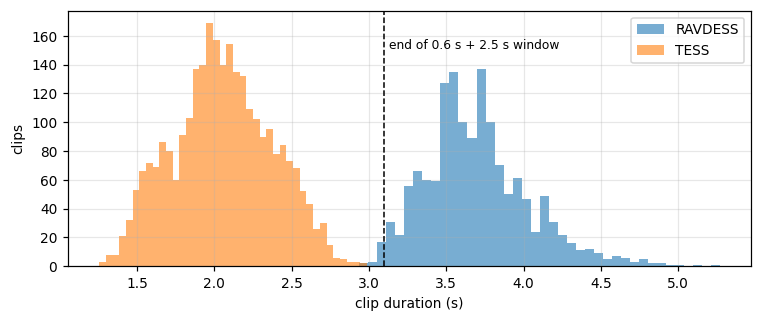

,mean,std,min,50%,max,% shorter than 3.1 s
dataset,,,,,,
RAVDESS,3.70,0.34,2.94,3.67,5.27,1.0
TESS,2.06,0.32,1.25,2.05,2.98,100.0


In [8]:
WINDOW_END = F.OFFSET + F.DURATION
fig, ax = plt.subplots(figsize=(7, 3))
for d, c in [("RAVDESS", "tab:blue"), ("TESS", "tab:orange")]:
    ax.hist(meta.loc[meta.dataset == d, "duration_s"], bins=40, alpha=0.6, label=d, color=c)
ax.axvline(WINDOW_END, color="k", ls="--", lw=1)
ax.text(WINDOW_END + 0.03, ax.get_ylim()[1] * 0.85, "end of 0.6 s + 2.5 s window", fontsize=8)
ax.set_xlabel("clip duration (s)"); ax.set_ylabel("clips"); ax.legend()
savefig("fig2_durations")
dur = meta.groupby("dataset")["duration_s"].describe()[["mean", "std", "min", "50%", "max"]].round(2)
dur["% shorter than 3.1 s"] = meta.groupby("dataset")["duration_s"].apply(lambda s: 100 * (s < WINDOW_END).mean()).round(1)
show(dur)

### 4.3 What the emotions look like
One RAVDESS clip per emotion (same actor and sentence) as a waveform and a log-mel spectrogram.

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


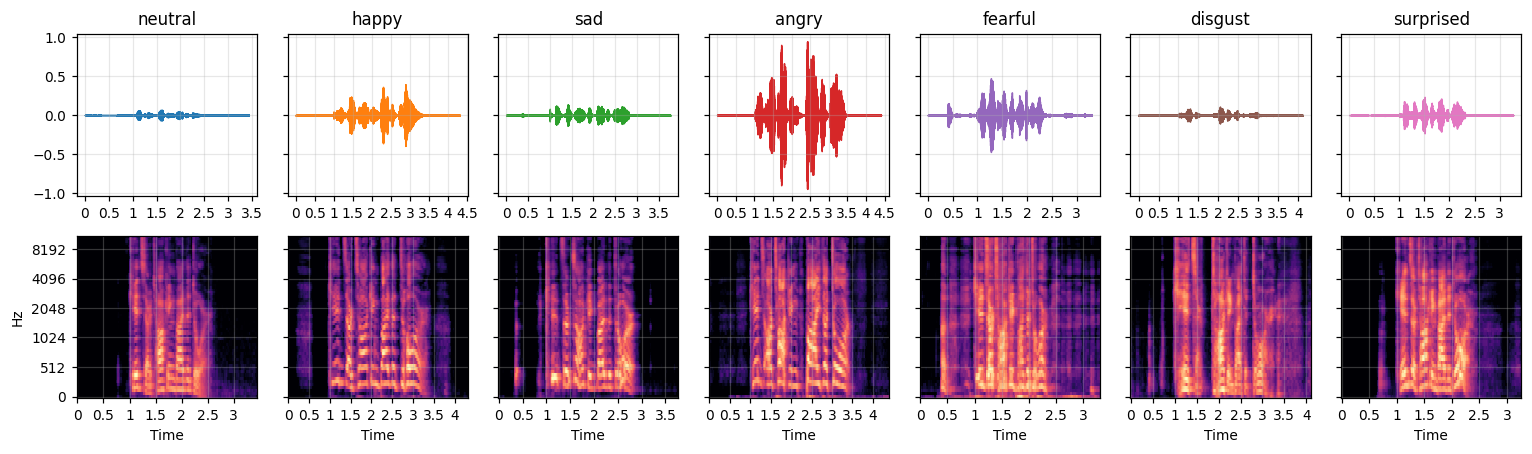

In [9]:
# Actor 03, statement 1, repetition 1; strong intensity (neutral only exists at normal intensity).
codes = {"neutral": "01-01", "happy": "03-02", "sad": "04-02", "angry": "05-02",
         "fearful": "06-02", "disgust": "07-02", "surprised": "08-02"}
names = {f"03-01-{c}-01-01-03.wav": e for e, c in codes.items()}
ex = rav[rav.path.map(lambda p: Path(p).name in names)].set_index("emotion").reindex(EMOTIONS)
fig, ax = plt.subplots(2, len(ex), figsize=(14, 4.2), sharey="row")
for j, (emo, row) in enumerate(ex.iterrows()):
    y, sr = librosa.load(row.path, sr=F.SR)
    librosa.display.waveshow(y, sr=sr, ax=ax[0, j], color=COLORS[emo])
    ax[0, j].set_title(emo); ax[0, j].set_xlabel("")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="mel", ax=ax[1, j])
    if j:
        ax[0, j].set_ylabel(""); ax[1, j].set_ylabel("")
savefig("fig3_waveforms_spectrograms")

## 5. Preprocessing pipeline

We follow the base paper exactly so that our later results are comparable with it:

1. **Load and resample** every clip to mono 22,050 Hz, reading **2.5 s from an offset of 0.6 s**
   (the offset skips the leading silence before the actor speaks).
2. **Fixed length:** frame length 2,048, hop 512 → **108 frames**; clips shorter than the window are
   **zero-filled** (the paper: "null values were replaced with zeroes").
3. **Features per frame:** zero-crossing rate (1), RMS energy (1), 20 MFCCs, 12 Chroma-STFT bins → a
   **108 × 34** matrix per clip; flattened this is the paper's **3,672-value** vector.
4. **Augmentation (training data only):** Gaussian noise (α = 0.035 × peak), pitch shift (+0.7 semitone)
   and noise + pitch, giving 4 versions of every clip. Augmentation is seeded per file name.
5. **Normalisation:** each of the 3,672 dimensions is standardised (z-score) with mean/std computed on the
   *training split only*, inside the experiment code, so no test statistics leak into training.

*Change from the Phase 1 proposal:* we planned silence trimming and time-stretch augmentation. We dropped
both to reproduce the paper's pipeline faithfully; the fixed 0.6 s offset already removes leading silence,
and the paper uses only noise and pitch augmentation.

raw: 211411 samples @ 48000 Hz (4.40 s)  ->  loaded window: 55125 samples @ 22050 Hz (2.50 s)
frame feature matrix: (108, 34) -> flattened: (1, 3672)


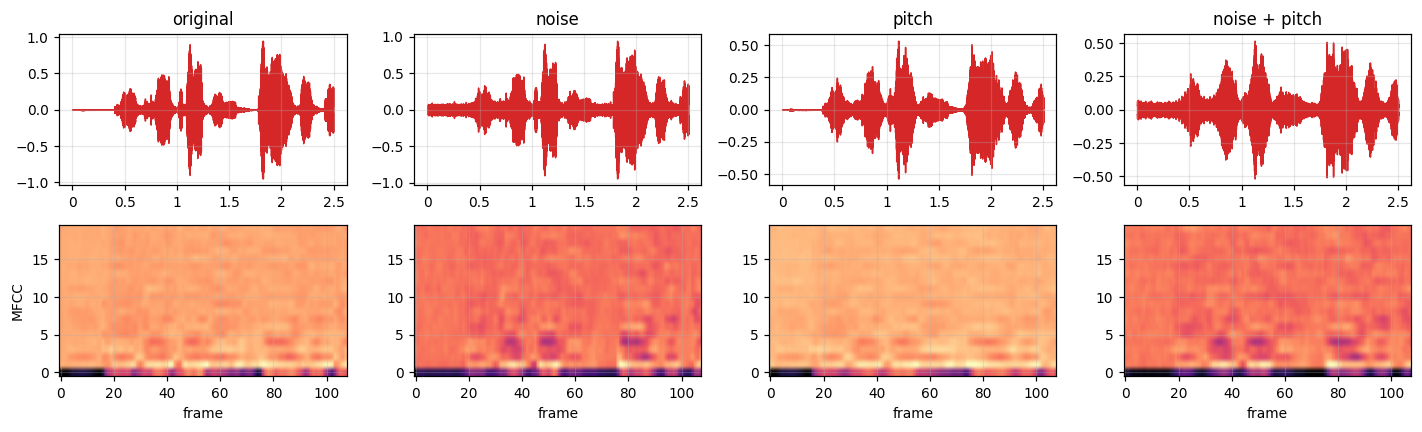

In [10]:
row = ex.loc["angry"]
y_raw, sr_raw = sf.read(row.path)
y = F.load_audio(row.path)
print(f"raw: {len(y_raw)} samples @ {sr_raw} Hz ({len(y_raw) / sr_raw:.2f} s)  ->  "
      f"loaded window: {len(y)} samples @ {F.SR} Hz ({len(y) / F.SR:.2f} s)")
fm = F.frame_features(y)
print("frame feature matrix:", fm.shape, "-> flattened:", F.flatten(fm[None]).shape)

rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(2, 4, figsize=(13, 4))
for j, kind in enumerate(F.AUGMENTATIONS):
    ya = F.augment(y, kind, rng)
    librosa.display.waveshow(ya, sr=F.SR, ax=ax[0, j], color="tab:red")
    ax[0, j].set_title(kind.replace("_", " + ")); ax[0, j].set_xlabel("")
    m = F.frame_features(ya)[:, F.FEATURE_GROUPS["mfcc"]].T
    ax[1, j].imshow(m, aspect="auto", origin="lower", cmap="magma")
    ax[1, j].set_xlabel("frame"); ax[1, j].set_ylabel("MFCC" if j == 0 else "")
savefig("fig4_augmentation")

**Feature extraction for all clips.** `scripts/extract_features.py` applies steps 1–4 to all 4,240 clips in
parallel (~8 min on 4 CPU cores) and caches the result in `features/` as `ravdess.npz` / `tess.npz`
(array shape: clips × 4 versions × 108 frames × 34 features) plus a metadata CSV.

In [11]:
if not (FEAT / "ravdess.npz").exists() or not (FEAT / "tess.npz").exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "extract_features.py")], cwd=ROOT, check=True)
X = {d: np.load(FEAT / f"{d.lower()}.npz")["X"] for d in ("RAVDESS", "TESS")}
M = {d: pd.read_csv(FEAT / f"{d.lower()}.csv") for d in ("RAVDESS", "TESS")}
for d in X:
    x = X[d]
    pad = (np.abs(x[:, 0]).sum(axis=2) == 0).mean()   # all-zero frames of the original version
    print(f"{d}: {x.shape} ({x.nbytes / 2**20:.0f} MB, float32) | NaN/inf: {int((~np.isfinite(x)).sum())} | "
          f"zero-filled frames: {100 * pad:.2f}%")

RAVDESS: (1440, 4, 108, 34) (81 MB, float32) | NaN/inf: 0 | zero-filled frames: 0.02%
TESS: (2800, 4, 108, 34) (157 MB, float32) | NaN/inf: 0 | zero-filled frames: 41.51%


## 6. EDA on the extracted features

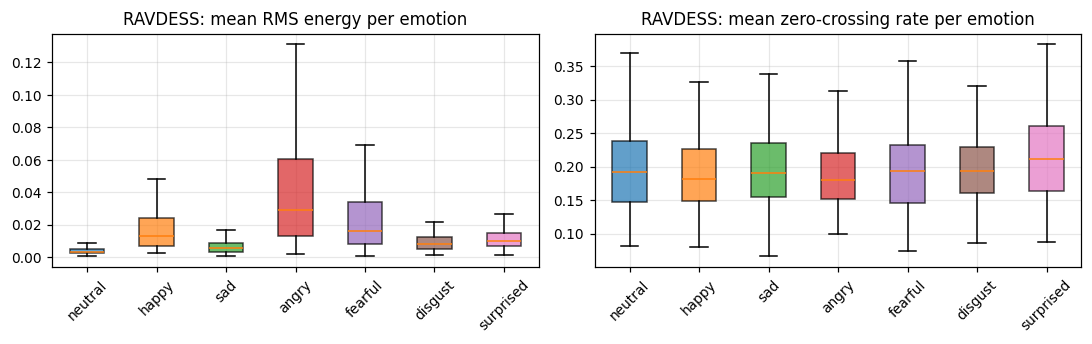

,rms,zcr
emotion,,
neutral,0.0034,0.1916
happy,0.0133,0.1808
sad,0.0054,0.1900
angry,0.0290,0.1808
fearful,0.0159,0.1939
disgust,0.0080,0.1938
surprised,0.0102,0.2109


In [12]:
def clip_stats(d):
    x = X[d][:, 0]                              # original (non-augmented) version
    voiced = np.abs(x).sum(axis=2) > 0          # ignore zero-filled frames
    mean = lambda col: np.array([x[i, voiced[i], col].mean() for i in range(len(x))])
    return M[d].assign(rms=mean(1), zcr=mean(0), mfcc1=mean(2))


S = {d: clip_stats(d) for d in X}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, col, title in [(ax[0], "rms", "mean RMS energy"), (ax[1], "zcr", "mean zero-crossing rate")]:
    data = [S["RAVDESS"].loc[S["RAVDESS"].emotion == e, col] for e in EMOTIONS]
    b = a.boxplot(data, tick_labels=EMOTIONS, patch_artist=True, showfliers=False)
    for p, e in zip(b["boxes"], EMOTIONS):
        p.set_facecolor(COLORS[e]); p.set_alpha(0.7)
    a.set_title(f"RAVDESS: {title} per emotion"); a.tick_params(axis="x", rotation=45)
savefig("fig5_energy_zcr")
show(S["RAVDESS"].groupby("emotion")[["rms", "zcr"]].median().reindex(EMOTIONS).round(4))

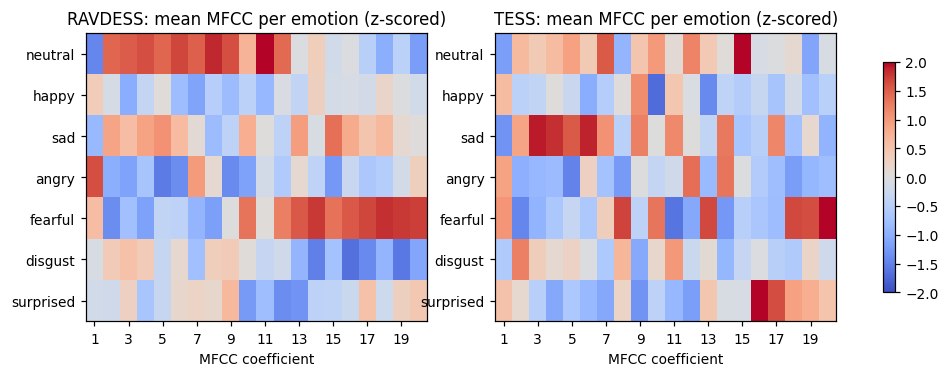

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, d in zip(ax, X):
    x = X[d][:, 0][:, :, F.FEATURE_GROUPS["mfcc"]]
    voiced = np.abs(X[d][:, 0]).sum(axis=2) > 0
    prof = np.stack([x[i, voiced[i]].mean(axis=0) for i in range(len(x))])
    tab = pd.DataFrame(prof).groupby(M[d].emotion.values).mean().reindex(EMOTIONS)
    tab = (tab - tab.mean()) / tab.std()        # z-score per coefficient to show contrasts
    im = a.imshow(tab.values, aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
    a.set_yticks(range(7), EMOTIONS); a.set_xticks(range(0, 20, 2), range(1, 21, 2))
    a.set_xlabel("MFCC coefficient"); a.set_title(f"{d}: mean MFCC per emotion (z-scored)"); a.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.savefig(FIG / "fig6_mfcc_profiles.png", dpi=200, bbox_inches="tight"); plt.show()

### 6.1 Dataset shift between RAVDESS and TESS
A 2-D PCA of clip-level features (mean and std of the 34 features over voiced frames, standardised).

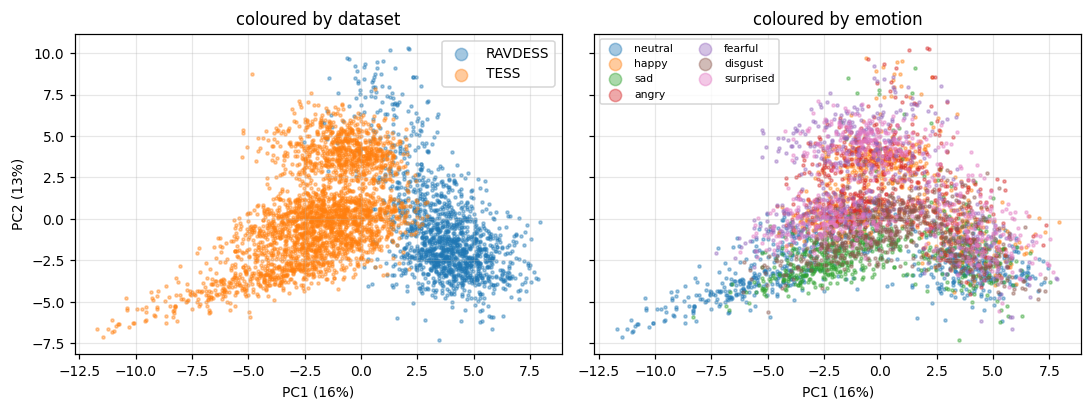

In [14]:
def pooled_voiced(d):
    x = X[d][:, 0]
    voiced = np.abs(x).sum(axis=2) > 0
    return np.stack([np.r_[x[i, voiced[i]].mean(0), x[i, voiced[i]].std(0)] for i in range(len(x))])


P = np.vstack([pooled_voiced("RAVDESS"), pooled_voiced("TESS")])
P = (P - P.mean(0)) / (P.std(0) + 1e-8)
pca = PCA(2, random_state=SEED).fit(P)
Z = pca.transform(P)
lab = np.r_[M["RAVDESS"].emotion, M["TESS"].emotion]
src = np.r_[["RAVDESS"] * len(M["RAVDESS"]), ["TESS"] * len(M["TESS"])]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
for d, c in [("RAVDESS", "tab:blue"), ("TESS", "tab:orange")]:
    ax[0].scatter(*Z[src == d].T, s=4, alpha=0.4, color=c, label=d)
ax[0].legend(markerscale=4); ax[0].set_title("coloured by dataset")
for e in EMOTIONS:
    ax[1].scatter(*Z[lab == e].T, s=4, alpha=0.4, color=COLORS[e], label=e)
ax[1].legend(markerscale=4, fontsize=7, ncol=2); ax[1].set_title("coloured by emotion")
for a in ax:
    a.set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}%)")
ax[0].set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}%)")
savefig("fig7_pca_shift")

## 7. Splits used in the experiments

Splits are made on **clips**, and augmentation is applied **after** splitting (only training clips get
augmented copies), so no version of a test clip is ever seen in training. All splits use seed 42 and are
stratified by emotion; the code below mirrors `scripts/run_experiments.py`.

In [15]:
yr = M["RAVDESS"].label.values
idx = np.arange(len(yr))
tr, rest = train_test_split(idx, test_size=0.2, stratify=yr, random_state=SEED)
val, te = train_test_split(rest, test_size=0.5, stratify=yr[rest], random_state=SEED)
assert not set(tr) & set(val) and not set(tr) & set(te) and not set(val) & set(te)

FOLDS = [list(range(1, 7)), list(range(7, 13)), list(range(13, 19)), list(range(19, 25))]
actors = M["RAVDESS"].actor.values


def split_row(name, tr, val, n_test):
    return {"protocol": name, "train clips": len(tr), "train samples (x4 aug.)": 4 * len(tr),
            "val clips": len(val), "test clips": n_test}


rows = [split_row("P1 random 80/10/10 (paper)", tr, val, len(te))]
for k, a in enumerate(FOLDS):
    pool = idx[~np.isin(actors, a)]            # training actors; 10% of their clips -> validation
    ftr, fval = train_test_split(pool, test_size=0.1, stratify=yr[pool], random_state=SEED)
    assert not set(actors[ftr]) & set(a)       # no test speaker in training
    rows.append(split_row(f"P2 speaker fold {k + 1} (test actors {a[0]}-{a[-1]})", ftr, fval, int(np.isin(actors, a).sum())))
ctr, cval = train_test_split(idx, test_size=0.1, stratify=yr, random_state=SEED)
rows.append(split_row("P3 RAVDESS -> TESS (all of TESS is test)", ctr, cval, len(M["TESS"])))
splits = pd.DataFrame(rows)
show(splits)
side = {i: "train" if i in set(tr) else "val" if i in set(val) else "test" for i in dup_idx}
print("duplicate pair in P1 split:", side)
print("P1 test-set class counts:", dict(zip(*np.unique(M["RAVDESS"].emotion.values[te], return_counts=True))))
print("each speaker fold holds out 3 male + 3 female actors:",
      [int((np.array(a) % 2).sum()) for a in FOLDS])

,protocol,train clips,train samples (x4 aug.),val clips,test clips
0,P1 random 80/10/10 (paper),1152,4608,144,144
1,P2 speaker fold 1 (test actors 1-6),972,3888,108,360
2,P2 speaker fold 2 (test actors 7-12),972,3888,108,360
3,P2 speaker fold 3 (test actors 13-18),972,3888,108,360
4,P2 speaker fold 4 (test actors 19-24),972,3888,108,360
5,P3 RAVDESS -> TESS (all of TESS is test),1296,5184,144,2800


duplicate pair in P1 split: {374: 'val', 375: 'train'}
P1 test-set class counts: {'angry': np.int64(19), 'disgust': np.int64(19), 'fearful': np.int64(20), 'happy': np.int64(19), 'neutral': np.int64(29), 'sad': np.int64(19), 'surprised': np.int64(19)}
each speaker fold holds out 3 male + 3 female actors: [3, 3, 3, 3]


In [16]:
# Normalisation, as applied inside the experiments: statistics from training clips only.
V_tr = F.flatten(X["RAVDESS"][tr].reshape(-1, F.N_FRAMES, F.N_FEATURES))
mu, sd = V_tr.mean(0), V_tr.std(0) + 1e-8
V_te = (F.flatten(X["RAVDESS"][te, 0]) - mu) / sd
print("model input per sample:", V_tr.shape[1], "values | train matrix:", V_tr.shape,
      f"| test after scaling: mean {V_te.mean():.3f}, std {V_te.std():.3f}")

model input per sample: 3672 values | train matrix: (4608, 3672) | test after scaling: mean -0.036, std 1.098


## 8. Final dataset summary

In [17]:
summary = pd.DataFrame({
    "clips": [len(M["RAVDESS"]), len(M["TESS"])],
    "speakers": ["24 (12 M / 12 F)", "2 (F)"],
    "classes": [M["RAVDESS"].emotion.nunique(), M["TESS"].emotion.nunique()],
    "versions per clip": [X["RAVDESS"].shape[1], X["TESS"].shape[1]],
    "feature matrix per clip": ["108 x 34", "108 x 34"],
    "model input": ["3,672 values", "3,672 values"],
    "cached array": [str(X["RAVDESS"].shape), str(X["TESS"].shape)],
}, index=["RAVDESS", "TESS"])
show(summary.T)
out = meta.drop(columns=["md5"]).assign(path=meta.path.map(lambda p: str(Path(p).relative_to(ROOT))))
out.to_csv(ROOT / "phase2" / "dataset_index.csv", index=False)
print("saved phase2/dataset_index.csv with", len(out), "rows")

,RAVDESS,TESS
clips,1440,2800
speakers,24 (12 M / 12 F),2 (F)
classes,7,7
versions per clip,4,4
feature matrix per clip,108 x 34,108 x 34
model input,"3,672 values","3,672 values"
cached array,"(1440, 4, 108, 34)","(2800, 4, 108, 34)"


saved phase2/dataset_index.csv with 4240 rows


## 9. Key insights

1. **Clean but not perfect.** No unreadable, silent or unlabelled files. The official RAVDESS release
   contains 5 stereo files and one recording stored under two names; TESS has one file at 96 kHz. All are
   handled by mono conversion and resampling; the duplicate is documented and tracked through the splits.
2. **Balanced classes, with one exception.** TESS has exactly 400 clips per emotion. RAVDESS has 192 per
   emotion except *neutral* (288 after merging *calm*), so neutral is 20 % of RAVDESS: we report macro-F1
   next to accuracy.
3. **Gender-balanced RAVDESS, female-only TESS.** RAVDESS has 720 male and 720 female clips with identical
   emotion/intensity counts, so the gender-bias check is fair; TESS (2 female speakers) cannot be used for it.
4. **Clip length is a hidden difference between the datasets.** RAVDESS clips average 3.70 s, TESS
   2.06 s. With the paper's 0.6 s offset and 2.5 s window, 100 % of TESS clips are shorter than the window
   (41.5 % of TESS frames are zero-filled) against 1 % of RAVDESS clips (0.02 % of frames). A model trained
   on RAVDESS never sees this padding, which is a warning for the cross-dataset test.
5. **Arousal shows in simple features.** Median RMS energy of *angry* clips is about 8.5x that of
   *neutral* (0.029 vs 0.0034); happy, fearful and surprised are also loud, while neutral and sad are quiet.
   ZCR alone separates emotions poorly. MFCC profiles give each emotion a distinct pattern.
6. **Strong dataset shift.** In PCA space RAVDESS and TESS form two largely separate clusters, and the
   MFCC pattern of the same emotion differs between the corpora. We therefore expect within-dataset
   accuracy to overstate real-world generalisation; this is what Phase 3 tests.
7. **No leakage by construction.** Splits are made on clips (or speakers) before augmentation, all four
   versions of a clip stay on one side, and standardisation uses training statistics only.